<a href="https://colab.research.google.com/github/giovanardo/Data-201---Project-1/blob/main/project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Classification in Practice

## The Big Question: How can we build and evaluate classification models to make predictions about a real-world outcome?

Dataset: Breast Cancer

Response: Malignant or benign

Scenario: You are analyzing measurements collected from breast masses. Your goal is to determine whether these measurements can be used to classify a mass as malignant or benign. Think carefully about the consequences of incorrectly classifying a malignant tumor as benign.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
#from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    mean_squared_error,
    roc_auc_score
)

brca = pd.read_csv("/content/drive/MyDrive/data 201/Projects/datasets/brca.csv")

## Part 1: Understanding The Problem

In [4]:
brca.head()

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst,y
0,1,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259,B
1,2,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183,B
2,3,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773,B
3,4,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169,B
4,5,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409,B


In [5]:
brca.shape

(569, 32)

In [6]:
brca.describe() #looking quantitative variables

,Unnamed: 0,x.radius_mean,x.texture_mean,x.perimeter_mean,x.area_mean,x.smoothness_mean,x.compactness_mean,x.concavity_mean,x.concave_pts_mean,x.symmetry_mean,...,x.radius_worst,x.texture_worst,x.perimeter_worst,x.area_worst,x.smoothness_worst,x.compactness_worst,x.concavity_worst,x.concave_pts_worst,x.symmetry_worst,x.fractal_dim_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,285.000000,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,164.400426,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,1.000000,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,143.000000,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,285.000000,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,427.000000,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,569.000000,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Each row is one breast mass, and each feature describes the mass by measurements.

Only one variable is categorical, besides the ID and it divides the dataset into two groups: M = malignant, B = benign.

While inspecting the dataset and analyzing the mean of each variable, we will need to do some scaling.


In [7]:
brca['y'].value_counts()

,count
y,
B,357
M,212


In [8]:
brca["y"].value_counts(normalize=True)

,proportion
y,
B,0.627417
M,0.372583


In [9]:
brca.isna().sum().sum()

np.int64(0)

|                |   Predicted No |  Predicted Yes |
| -------------- | -------------: | -------------: |
| **Actual No**  |  True Negative | False Positive |
| **Actual Yes** | False Negative |  True Positive |

The dataset has 357 benign (62.7%) and 212 malignant (37.3%) masses. The classes are not balanced.

Malignant = positive

A false positive happens if the model predicts a mass as malignant but in fact the mass is benign: the patient will be submitted to other exams and be stressed out.

A false negative happens if the model predicts a mass as benign but in fact the mass is malignant: the patient will not receive the diagnostic, and the treatment will be delayed.

Because a false negative delays the treatment of a malignant mass, I am more concerned about false negatives than false positives, although false positives also have a cost (extra exams and stress).

## Part 2: Explore and Prepare the Data

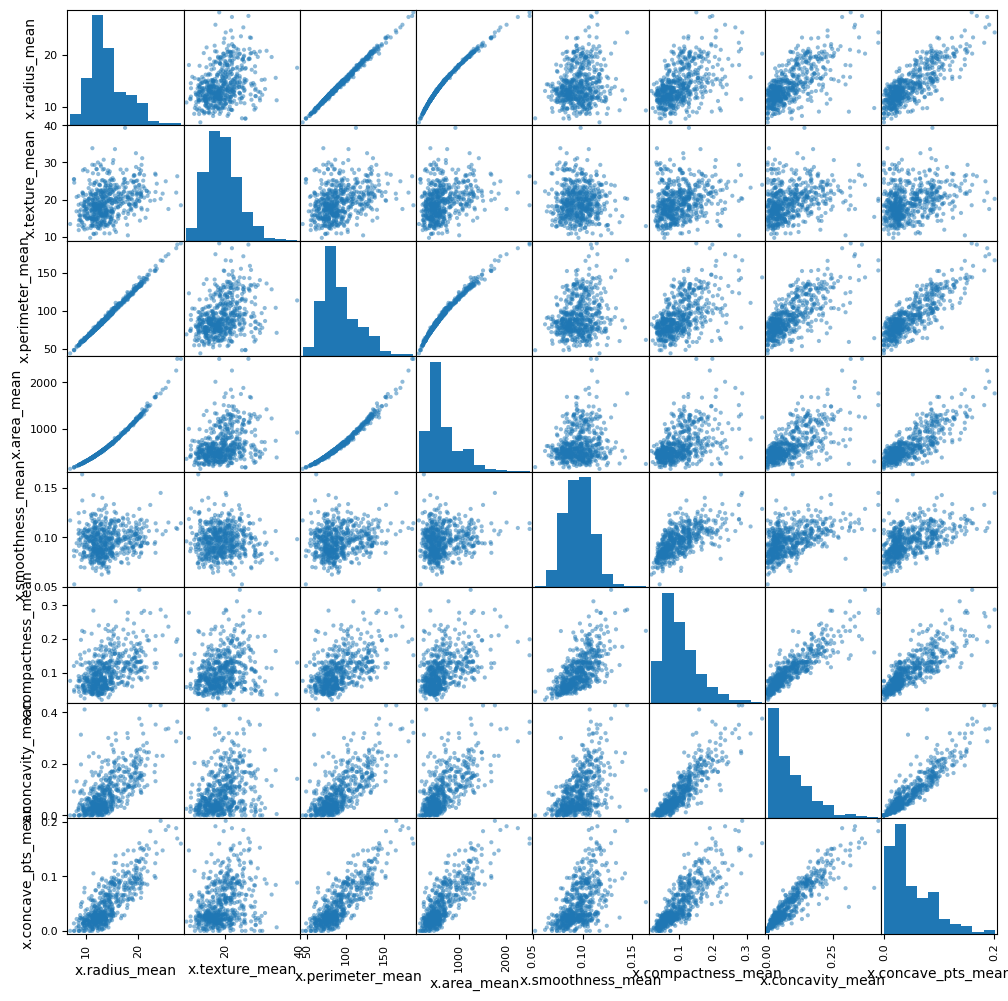

In [10]:
A = ["x.radius_mean","x.texture_mean","x.perimeter_mean", "x.area_mean", "x.smoothness_mean", "x.compactness_mean", "x.concavity_mean", "x.concave_pts_mean"]
pd.plotting.scatter_matrix(brca[A], figsize=(12,12));

Predictors chosen: radius, texture and concave points.

There are no missing values, so no imputation was needed.

Summary statistics by Diagnostic:
  x.radius_mean                     x.texture_mean                      \
           mean       std      skew           mean       std      skew   
y                                                                        
B     12.146524  1.780512 -0.083799      17.914762  3.995125  0.981344   
M     17.462830  3.203971  0.501902      21.604906  3.779470  0.703543   

  x.concave_pts_mean                      
                mean       std      skew  
y                                         
B           0.025717  0.015909  0.924965  
M           0.087990  0.034374  0.739092  
   x.radius_mean  x.texture_mean  x.concave_pts_mean
y                                                   
B       1.780512        3.995125            0.015909
M       3.203971        3.779470            0.034374


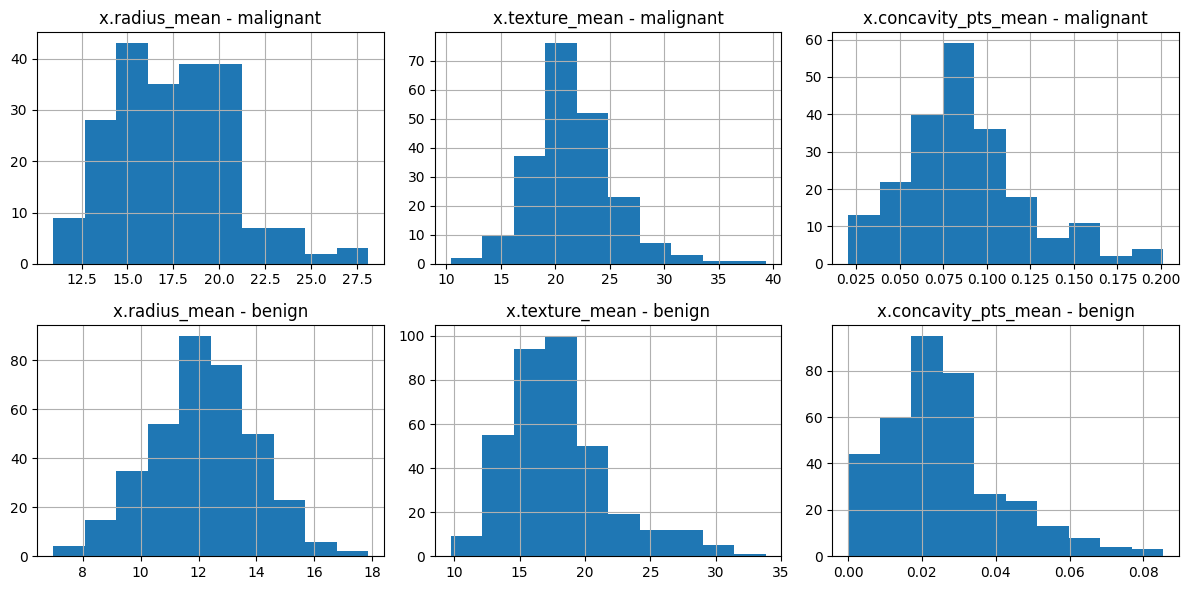

In [11]:
print("Summary statistics by Diagnostic:")
print(
    brca.groupby("y")[["x.radius_mean", "x.texture_mean", "x.concave_pts_mean"]].agg(
        ["mean", "std", "skew"]
    )
)

print(brca.groupby("y")[["x.radius_mean", "x.texture_mean", "x.concave_pts_mean"]].std())

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

brca[brca["y"] == "M"]["x.radius_mean"].hist(ax=axes[0,0])
axes[0,0].set_title("x.radius_mean - malignant")

brca[brca["y"] == "B"]["x.radius_mean"].hist(ax=axes[1,0])
axes[1,0].set_title("x.radius_mean - benign")

brca[brca["y"] == "M"]["x.texture_mean"].hist(ax=axes[0,1])
axes[0,1].set_title("x.texture_mean - malignant")

brca[brca["y"] == "B"]["x.texture_mean"].hist(ax=axes[1,1])
axes[1,1].set_title("x.texture_mean - benign")

brca[brca["y"] == "M"]["x.concave_pts_mean"].hist(ax=axes[0,2])
axes[0,2].set_title("x.concavity_pts_mean - malignant")

brca[brca["y"] == "B"]["x.concave_pts_mean"].hist(ax=axes[1,2])
axes[1,2].set_title("x.concavity_pts_mean - benign")

plt.tight_layout()
plt.show()

After analyzing the mean and standard deviation of each class and feature, we can conclude: malignant masses have larger mean radius (17.5 vs. 12.1) and more concave points (0.088 vs. 0.026) than benign masses, while texture differs more modestly (21.6 vs. 17.9).

The standard deviations of radius and concave points are almost twice as large in the malignant class, which creates a problem if we wanted to predict with LDA and suggests QDA may fit better.


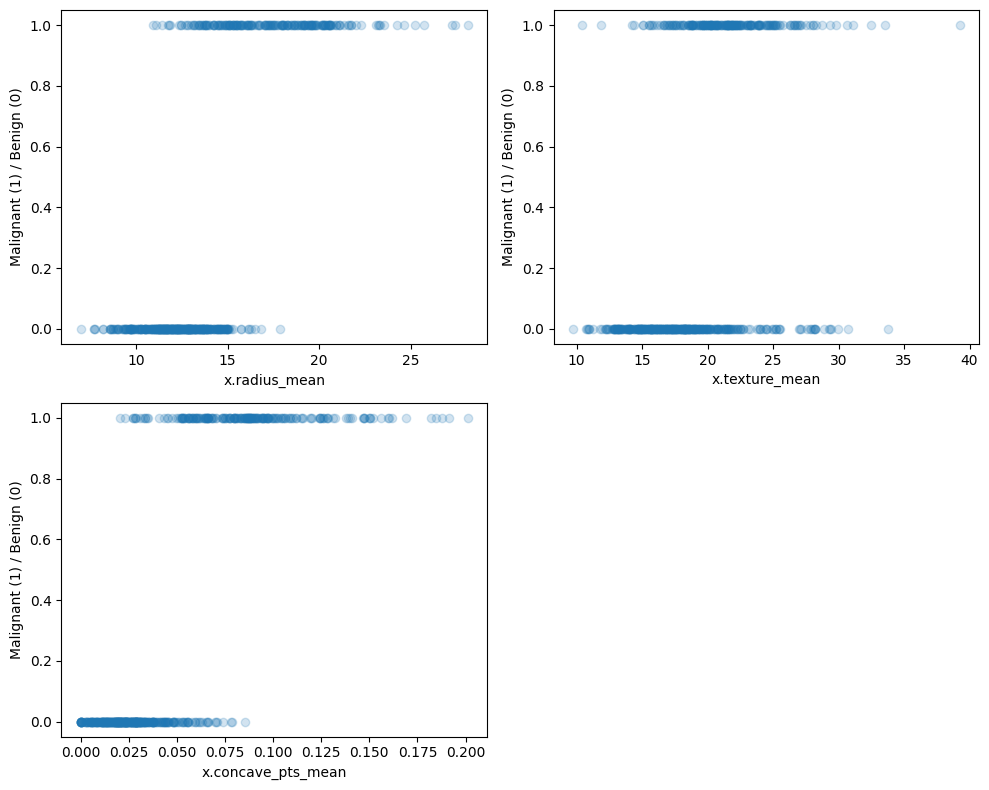

In [12]:
predictors = ["x.radius_mean", "x.texture_mean", "x.concave_pts_mean"]

plt.figure(figsize=(10, 8))

for i, var in enumerate(predictors, start=1):
    plt.subplot(2, 2, i)
    plt.scatter(
        brca[var],
        brca["y"].map({"M": 1, "B": 0}),
        alpha=0.2
    )
    plt.xlabel(var)
    plt.ylabel("Malignant (1) / Benign (0)")

plt.tight_layout()
plt.show()

The graph shows that the target overlap each other partly, so a boundary such as Logistic may fit.

In [13]:
brca["diagnostic_num"] = brca["y"].map({
    "M": 1,
    "B": 0
})

In [14]:
X = brca[["x.radius_mean", "x.texture_mean", "x.concave_pts_mean"]]
y = brca["diagnostic_num"]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

In [16]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

The data was split in 75/25 with stratification and used stratified 5-fold cross-validation only on the training set.

Standardization is needed for logistic regression and KNN and it is done inside a pipeline so it is learned only from the training folds. LDA and QDA do not need it.

## Part 3: Build Your Classifiers

### Logistic

In [17]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

logreg_grid = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    logreg,
    logreg_grid,
    cv=kfold,
    scoring='roc_auc'
)

grid_lr.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('logisticregression',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'logisticregression__C': [0.001, 0.01, 0.1, 1, 10,
                                                   100]},
             scoring='roc_auc')

## LDA

In [18]:
lda = LinearDiscriminantAnalysis()

lda_cv = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=kfold,
    scoring = 'roc_auc'
)

lda_cv

array([0.99710648, 0.97346698, 0.98879717, 0.97995283, 0.98685783])

## QDA

In [19]:
qda = QuadraticDiscriminantAnalysis()

qda_cv = cross_val_score(
    qda,
    X_train,
    y_train,
    cv=kfold,
    scoring='roc_auc'
)

qda_cv

array([0.99768519, 0.96757075, 0.99292453, 0.9817217 , 0.98267622])

In [20]:
print("Logistic best C:", grid_lr.best_params_, round(grid_lr.best_score_, 4))
print("LDA CV ROC-AUC:", round(lda_cv.mean(), 4), lda_cv.round(3))
print("QDA CV ROC-AUC:", round(qda_cv.mean(), 4), qda_cv.round(3))

Logistic best C: {'logisticregression__C': 0.01} 0.9864
LDA CV ROC-AUC: 0.9852 [0.997 0.973 0.989 0.98  0.987]
QDA CV ROC-AUC: 0.9845 [0.998 0.968 0.993 0.982 0.983]


## KNN

In [21]:
k_values = [1, 3, 5, 11, 21, 51, 71, 91]

cv_scores = []

for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring = 'roc_auc'
    )
    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.8992215149568314), np.float64(0.9634371266427719), np.float64(0.9667726155857622), np.float64(0.9732116893217014), np.float64(0.981465173519533), np.float64(0.9864277955298573), np.float64(0.9857768859471158), np.float64(0.9840111528144091)]


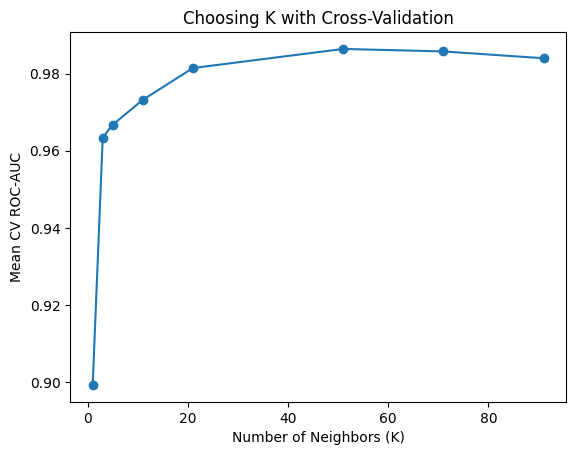

In [22]:
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV ROC-AUC")
plt.title("Choosing K with Cross-Validation")

plt.show()

In [23]:
best_k = k_values[int(np.argmax(cv_scores))]
print("Best K:", best_k)

best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)

best_knn.fit(X_train, y_train)

best_knn_pred = best_knn.predict(X_test)

#evaluate
accuracy_score(y_test, best_knn_pred)

Best K: 51


0.9440559440559441

In [24]:
best_lr = grid_lr.best_estimator_
lda.fit(X_train, y_train)
qda.fit(X_train, y_train)

prob_lr  = best_lr.predict_proba(X_test)[:, 1]
prob_lda = lda.predict_proba(X_test)[:, 1]
prob_qda = qda.predict_proba(X_test)[:, 1]
prob_knn = best_knn.predict_proba(X_test)[:, 1]

In [25]:
results = X_test.copy()
results["Actual"] = y_test.values
results["P(Malignant)"] = prob_lr
results["Prediction_0.50"] = (results["P(Malignant)"] >= 0.50).astype(int)
results["Prediction_0.20"] = (results["P(Malignant)"] >= 0.20).astype(int)
results.head(10)

,x.radius_mean,x.texture_mean,x.concave_pts_mean,Actual,P(Malignant),Prediction_0.50,Prediction_0.20
196,13.870,16.21,0.02088,0,0.211200,0,1
200,13.300,21.57,0.02424,0,0.275628,0,1
467,28.110,18.47,0.15950,1,0.965837,1,1
324,12.340,12.27,0.02647,0,0.148403,0,0
2,9.504,12.44,0.02076,0,0.093583,0,0
409,13.800,15.79,0.05069,1,0.295519,0,1
37,9.876,19.40,0.03029,0,0.174209,0,0
121,10.480,19.86,0.03070,0,0.194316,0,0
74,12.060,12.74,0.01963,0,0.133601,0,0
457,13.770,22.29,0.06526,1,0.458353,0,1


Predictions LOGISTIC

In [26]:
pred_50 = np.where(prob_lr >= 0.50, 1, 0)

cm = confusion_matrix(y_test,
                      pred_50,
                      labels=[0, 1])
print(cm)

TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, pred_50)
precision = precision_score(y_test, pred_50)
recall = recall_score(y_test, pred_50)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, pred_50)
auc = roc_auc_score(y_test, prob_lr)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("AUC:", auc)

[[90  0]
 [15 38]]
Accuracy: 0.8951048951048951
Precision: 1.0
Recall: 0.7169811320754716
Specificity: 1.0
F1: 0.8351648351648352
AUC: 0.9809224318658281


In [27]:
pred_20 = np.where(prob_lr >= 0.20, 1, 0)
cm20 = confusion_matrix(y_test,
                        pred_20,
                        labels=[0, 1])

print(cm20)

TN20, FP20, FN20, TP20 = cm20.ravel()

accuracy20 = accuracy_score(y_test, pred_20)
precision20 = precision_score(y_test, pred_20)
recall20 = recall_score(y_test, pred_20)
specificity20 = TN20 / (TN20 + FP20)
f120 = f1_score(y_test, pred_20)
auc20 = roc_auc_score(y_test, prob_lr)

print("Accuracy:", accuracy20)
print("Precision:", precision20)
print("Recall:", recall20)
print("Specificity:", specificity20)
print("F1:", f120)
print("AUC:", auc20)

[[47 43]
 [ 0 53]]
Accuracy: 0.6993006993006993
Precision: 0.5520833333333334
Recall: 1.0
Specificity: 0.5222222222222223
F1: 0.7114093959731543
AUC: 0.9809224318658281


Predictions LDA

In [28]:
pred_50 = np.where(prob_lda >= 0.50, 1, 0)

cm = confusion_matrix(y_test,
                      pred_50,
                      labels=[0, 1])
print(cm)

TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, pred_50)
precision = precision_score(y_test, pred_50)
recall = recall_score(y_test, pred_50)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, pred_50)
auc = roc_auc_score(y_test, prob_lda)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("AUC:", auc)

[[90  0]
 [10 43]]
Accuracy: 0.9300699300699301
Precision: 1.0
Recall: 0.8113207547169812
Specificity: 1.0
F1: 0.8958333333333334
AUC: 0.9844863731656184


In [29]:
pred_20 = np.where(prob_lda >= 0.20, 1, 0)
cm20 = confusion_matrix(y_test,
                        pred_20,
                        labels=[0, 1])

print(cm20)

TN20, FP20, FN20, TP20 = cm20.ravel()

accuracy20 = accuracy_score(y_test, pred_20)
precision20 = precision_score(y_test, pred_20)
recall20 = recall_score(y_test, pred_20)
specificity20 = TN20 / (TN20 + FP20)
f120 = f1_score(y_test, pred_20)
auc20 = roc_auc_score(y_test, prob_lda)

print("Accuracy:", accuracy20)
print("Precision:", precision20)
print("Recall:", recall20)
print("Specificity:", specificity20)
print("F1:", f120)
print("AUC:", auc20)

[[87  3]
 [ 7 46]]
Accuracy: 0.9300699300699301
Precision: 0.9387755102040817
Recall: 0.8679245283018868
Specificity: 0.9666666666666667
F1: 0.9019607843137255
AUC: 0.9844863731656184


Predictions QDA

In [30]:
pred_50 = np.where(prob_qda >= 0.50, 1, 0)

cm = confusion_matrix(y_test,
                      pred_50,
                      labels=[0, 1])
print(cm)

TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, pred_50)
precision = precision_score(y_test, pred_50)
recall = recall_score(y_test, pred_50)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, pred_50)
auc = roc_auc_score(y_test, prob_qda)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("AUC:", auc)

[[87  3]
 [ 6 47]]
Accuracy: 0.9370629370629371
Precision: 0.94
Recall: 0.8867924528301887
Specificity: 0.9666666666666667
F1: 0.912621359223301
AUC: 0.9834381551362683


In [31]:
pred_20 = np.where(prob_qda >= 0.20, 1, 0)
cm20 = confusion_matrix(y_test,
                        pred_20,
                        labels=[0, 1])

print(cm20)

TN20, FP20, FN20, TP20 = cm20.ravel()

accuracy20 = accuracy_score(y_test, pred_20)
precision20 = precision_score(y_test, pred_20)
recall20 = recall_score(y_test, pred_20)
specificity20 = TN20 / (TN20 + FP20)
f120 = f1_score(y_test, pred_20)
auc20 = roc_auc_score(y_test, prob_qda)

print("Accuracy:", accuracy20)
print("Precision:", precision20)
print("Recall:", recall20)
print("Specificity:", specificity20)
print("F1:", f120)
print("AUC:", auc20)

[[79 11]
 [ 3 50]]
Accuracy: 0.9020979020979021
Precision: 0.819672131147541
Recall: 0.9433962264150944
Specificity: 0.8777777777777778
F1: 0.8771929824561403
AUC: 0.9834381551362683


Predictions KNN

In [32]:
pred_50 = np.where(prob_knn >= 0.50, 1, 0)

cm = confusion_matrix(y_test,
                      pred_50,
                      labels=[0, 1])
print(cm)

TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, pred_50)
precision = precision_score(y_test, pred_50)
recall = recall_score(y_test, pred_50)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, pred_50)
auc = roc_auc_score(y_test, prob_knn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("AUC:", auc)

[[90  0]
 [ 8 45]]
Accuracy: 0.9440559440559441
Precision: 1.0
Recall: 0.8490566037735849
Specificity: 1.0
F1: 0.9183673469387755
AUC: 0.980293501048218


In [33]:
pred_20 = np.where(prob_knn >= 0.20, 1, 0)
cm20 = confusion_matrix(y_test,
                        pred_20,
                        labels=[0, 1])

print(cm20)

TN20, FP20, FN20, TP20 = cm20.ravel()

accuracy20 = accuracy_score(y_test, pred_20)
precision20 = precision_score(y_test, pred_20)
recall20 = recall_score(y_test, pred_20)
specificity20 = TN20 / (TN20 + FP20)
f120 = f1_score(y_test, pred_20)
auc20 = roc_auc_score(y_test, prob_knn)

print("Accuracy:", accuracy20)
print("Precision:", precision20)
print("Recall:", recall20)
print("Specificity:", specificity20)
print("F1:", f120)
print("AUC:", auc20)

[[79 11]
 [ 4 49]]
Accuracy: 0.8951048951048951
Precision: 0.8166666666666667
Recall: 0.9245283018867925
Specificity: 0.8777777777777778
F1: 0.8672566371681416
AUC: 0.980293501048218


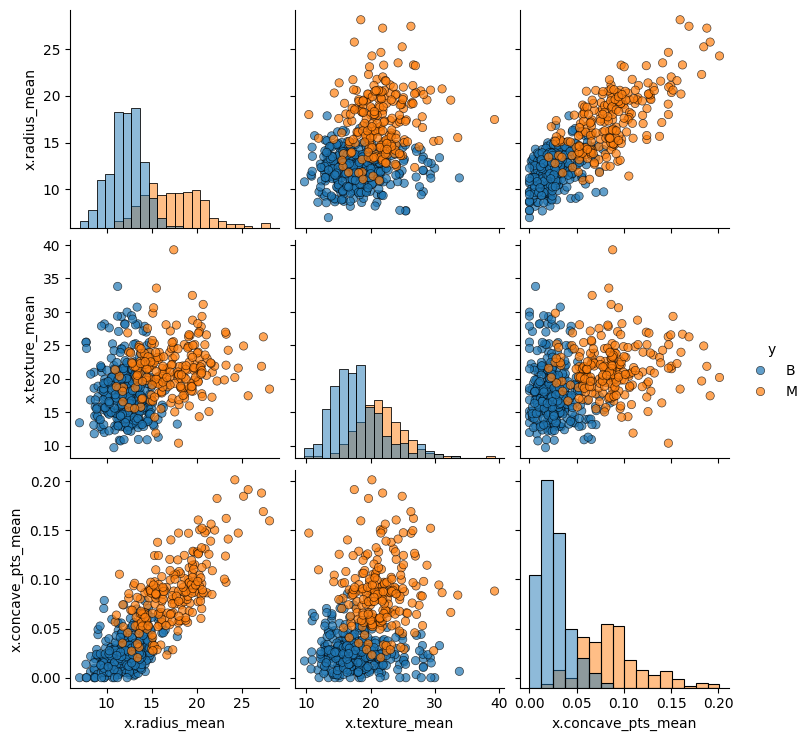

In [34]:
import seaborn as sns

sns.pairplot(
    brca,
    vars=["x.radius_mean", "x.texture_mean", "x.concave_pts_mean"],
    hue="y",
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "edgecolor": "k"}
)
plt.show()

This graph shows the three predictors. Each dot is a breast mass, blue for benign and orange for malignant. The diagonal shows the distribution of each variable, and the other panels compare two variables at a time.

Malignant masses tend to have larger radius and more concave points than benign ones, but the classes overlap in the middle, where the model makes mistakes.

**Threshold 0.50**

| Model | Accuracy | Precision | Recall | Specificity | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.895 | 1.000 | 0.717 | 1.000 | 0.835 | 0.981 |
| LDA | 0.930 | 1.000 | 0.811 | 1.000 | 0.896 | 0.984 |
| QDA | 0.937 | 0.940 | 0.887 | 0.967 | 0.913 | 0.983 |
| KNN | 0.944 | 1.000 | 0.849 | 1.000 | 0.918 | 0.980 |

**Threshold 0.20**

| Model | Accuracy | Precision | Recall | Specificity | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.699 | 0.552 | 1.000 | 0.522 | 0.711 | 0.981 |
| LDA | 0.930 | 0.939 | 0.868 | 0.967 | 0.902 | 0.984 |
| QDA | 0.902 | 0.820 | 0.943 | 0.878 | 0.877 | 0.983 |
| KNN | 0.895 | 0.817 | 0.925 | 0.878 | 0.867 | 0.980 |

## Part 5: Reflect

The four predictions have a Roc-Auc output (about 0.98), displaying that all models have similar performance. The difference appears when we choose a threshold;

In this analysis we wanted to avoid false negatives in order to prevent the delay on the treatment. The main result in this case would be Recall, because it is healthy related and the metric measures the misses.
Specify and Precision measures how much of the benign and malignant masses were correctly predicted. F1 measures the trade-off and Accuracy gives, for us, the less informative metric because the classes are not balanced.

At threshold is 0.50, LR has the smallest recall of all the models. Overall, The logistic model selected C = 0.01, a small C, so 0.20 is too strict for it.

Additionally, at the threshold is 0.20, the false negatives reach a lower number on all four models, but false positives increase and specificity falls.

## Part 6: ROC and AUC

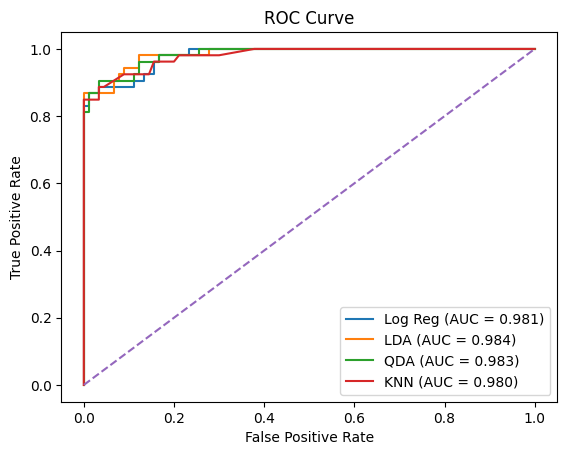

In [35]:
fpr, tpr, thresholds = roc_curve(y_test, prob_lr)
plt.plot(fpr, tpr, label=f"Log Reg (AUC = {roc_auc_score(y_test, prob_lr):.3f})")


fpr, tpr, thresholds = roc_curve(y_test, prob_lda)
auc_lda = roc_auc_score(y_test, prob_lda)
plt.plot(fpr, tpr, label=f"LDA (AUC = {auc_lda:.3f})")

fpr, tpr, thresholds = roc_curve(y_test, prob_qda)
auc_qda = roc_auc_score(y_test, prob_qda)
plt.plot(fpr, tpr, label=f"QDA (AUC = {auc_qda:.3f})")

fpr, tpr, thresholds = roc_curve(y_test, prob_knn)
auc_knn = roc_auc_score(y_test, prob_knn)
plt.plot(fpr, tpr, label=f"KNN (AUC = {auc_knn:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

An AUC of 0.98 means the model does a great job separating malignant masses from benign masses across all possible classification threshold.

The ROC curve shows that the model is not predicting random, all four models have a well ranking.

The threshold changes the confusion matrix and metrics like recall and precision, but the ROC-AUC summarizes the model’s discrimination across all thresholds rather than depending on just 0.50 or 0.20.

## Part 7: Final Analysis

| Model | FN (0.50) | FP (0.50) | FN (0.20) | FP (0.20)
|---|---:|---:|---:|---:|
| Log Reg | 15 | 0 | 0 | 43 |
| LDA | 10 | 0 | 7 | 3 |
| QDA | 6 | 3 | 3 | 11 |
| KNN | 8 | 0 | 4 | 11 |

### Comparing:
All four classifiers have almost the same ROC-AUC and overall, they rank malignant and benign masses similarly. The important differences appear in the errors at a given threshold.

At 0.50, logistic regression, LDA and KNN make no false positives, but they miss many malignant masses (15, 10 and 8). QDA has the fewest false negatives (6) with only 3 false positives.

At 0.20, false negatives drop for all models. Logistic regression misses none but returns 43 benign masses to extra testing. LDA has only 3 false positives but still misses 7 malignant masses. QDA (3 false negatives, 11 false positives) and KNN (4 and 11) are in between, and QDA is slightly better.

### Identifying the model:

I would deploy QDA with a threshold of 0.20. In this problem a false negative means a malignant mass classified as benign, which can delay treatment. QDA has the fewest false negatives at 0.50 and, at 0.20, the best balance; The cost is some benign masses sent for extra tests, which is more acceptable than a missed cancer.

QDA also matches what we saw in the data exploration: the standard deviations of radius and concave points were almost twice as large in the malignant class, which goes against the equal covariance assumption of LDA.

### Limitation:
The model uses only three measurements of the mass (mean radius, mean texture and mean concave points), selected by looking at the histograms. Because of this, two masses with similar measurements get similar predictions, even when other information could change the diagnosis. The predictors were also chosen by visual inspection, so a better combination of variables may exist, and some of them (for example radius and concave points) carry overlapping information(corr = 0.82), while mean texture is weakly correlated with the other two (corr = 0.32 and 0.29), so it adds mostly different information.

### Applying to the real world:

More predictors, for example: patient age, family history, other measurements of the mass, imaging results and the real follow-up outcome after biopsy to confirm the labels will help to check if the model actually works. Finally, I would work with doctors to estimate the real cost of a false negative versus a false positive, to choose the threshold with a proper perspective.